In [1]:
%pip install numpy 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 24.3.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 24.3.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 24.3.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
%pip install tensorflow tensorflow-gpu opencv-python matplotlib 

  Using cached tensorflow-gpu-2.12.0.tar.gz (2.6 kB)
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> [44 lines of output]
      Traceback (most recent call last):
        File "C:\Users\leena\AppData\Roaming\Python\Python312\site-packages\packaging\requirements.py", line 36, in __init__
          parsed = _parse_requirement(requirement_string)
                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        File "C:\Users\leena\AppData\Roaming\Python\Python312\site-packages\packaging\_parser.py", line 62, in parse_requirement
          return _parse_requirement(Tokenizer(source, rules=DEFAULT_RULES))
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        File "C:\Users\leena\AppData\Roaming\Python\Python312\site-packages\packaging\_parser.py", line 80, in _parse_requirement
          url, specifier, marker = _parse_requirement_details(tokenizer)
                                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        File "C:\User

In [5]:
%pip install opencv-python

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 24.3.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import tensorflow as tf
import os

In [7]:
gpus = tf.config.experimental.list_physical_devices('GPU')

In [8]:
len(gpus)

0

In [9]:
# Avoid OOM errors by setting Gpu Memory Consumption Growth
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus: 
    tf.config. experimental.set_memory_growth(gpu, True)

In [10]:
import cv2
import imghdr
from matplotlib import pyplot as plt

C:\Users\leena\AppData\Local\Temp\ipykernel_19228\3427753027.py:2: DeprecationWarning: 'imghdr' is deprecated and slated for removal in Python 3.13
  import imghdr


In [11]:
data_dir = 'data'
os.listdir(data_dir)


['Happy', 'Sad']

In [12]:
image_exts = ['jpeg', 'jpg', 'bmp', 'png']
image_exts

['jpeg', 'jpg', 'bmp', 'png']

In [13]:
for image_class in os.listdir(data_dir): 
    for image in os.listdir(os.path.join(data_dir, image_class)):
        image_path = os.path.join(data_dir, image_class, image)
        try: 
            img = cv2.imread(image_path)
            tip = imghdr.what(image_path)
            if tip not in image_exts: 
                print("Image not in ext list {}".format(image_path))
                os.remove(image_path)
        except Exception as e: 
            print('Isuue with image {}'.format(image_path))
            #os.remove(image_path)
        

In [14]:
import numpy as np 
from matplotlib import pyplot as plt

In [15]:
data = tf.keras.utils.image_dataset_from_directory('data')

Found 206 files belonging to 2 classes.


In [16]:
data_iterator = data.as_numpy_iterator()

In [17]:
# Get another batch from the iterator
batch = data_iterator.next()

In [18]:
#Images represented as numpy arrays
batch[0].shape

(32, 256, 256, 3)

In [19]:
# Class 1 = Sad ppl
# Class 0 = Happy ppl
batch[1]

array([1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0,
       1, 0, 1, 1, 0, 1, 1, 1, 0, 1], dtype=int32)

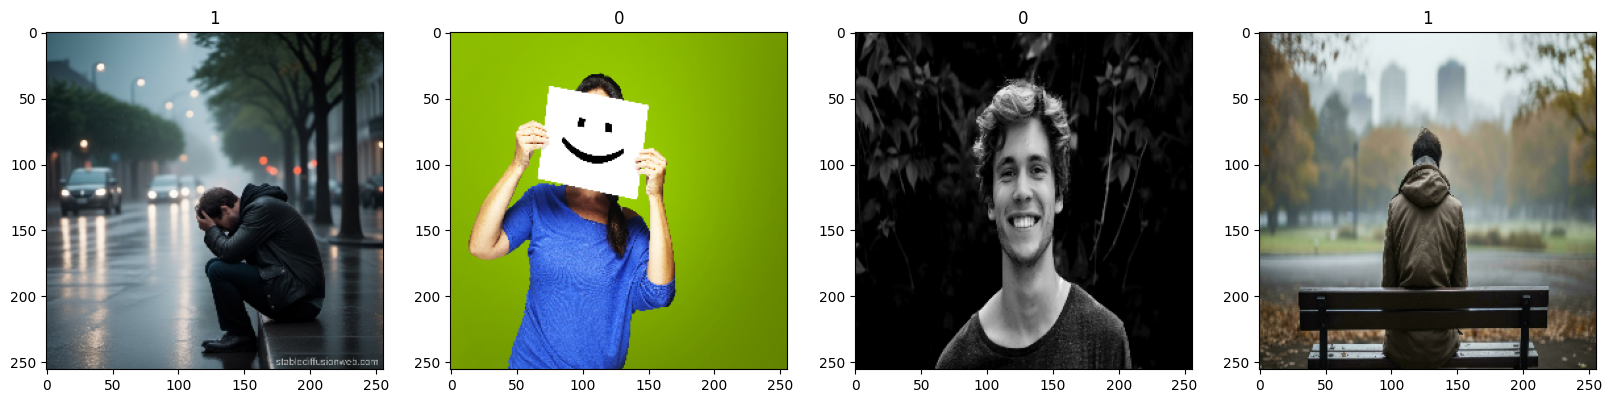

In [25]:
fig, ax = plt.subplots(ncols=4, figsize=(20, 20))
for idx, img in enumerate(batch[0][:4]): 
    ax[idx].imshow(img)
    ax[idx].title.set_text(batch[1][idx])

In [21]:
data = data.map(lambda x, y: (x/255, y))
scaled = batch[0] 
scaled.max()

np.float32(255.0)

In [22]:
scaled_iterator = data.as_numpy_iterator()

In [23]:
batch = scaled_iterator.next()

In [24]:
batch[0].min()

np.float32(0.0)

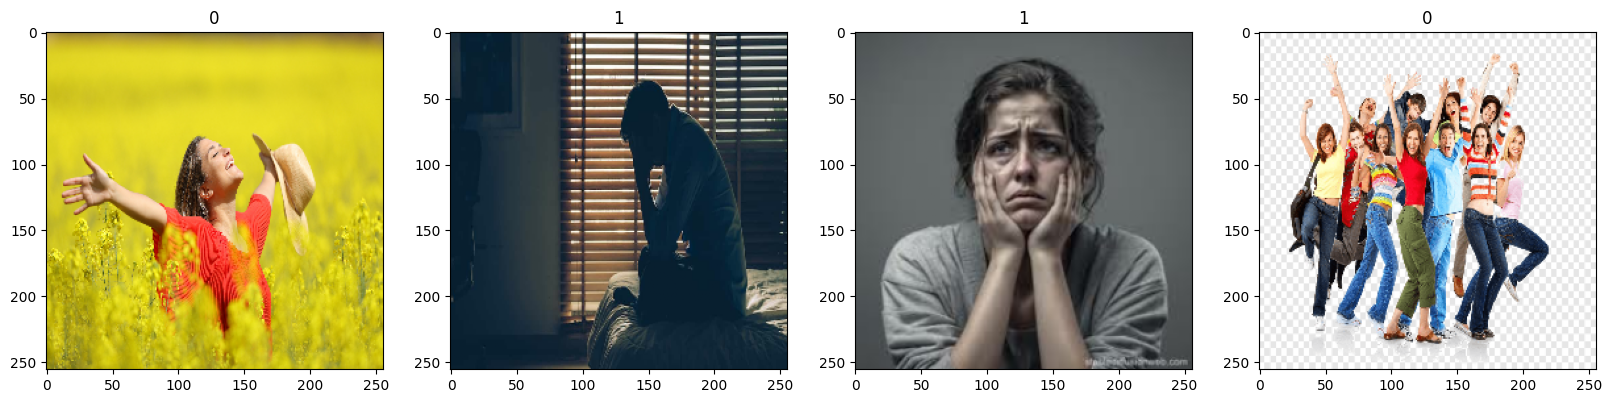

In [21]:
fig, ax = plt.subplots(ncols=4, figsize=(20, 20))
for idx, img in enumerate(batch[0][:4]): 
    ax[idx].imshow(img)
    ax[idx].title.set_text(batch[1][idx])

In [26]:
len(data)

7

In [27]:
train_size = int(len(data)* .7)
val_size = int(len(data)*.2)+1
test_size = int(len(data)*.1)+1

In [28]:
train_size+val_size+test_size

7

In [29]:
train = data.take(train_size)
val = data.skip(train_size).take(val_size)
test = data.skip(train_size+val_size).take(test_size)

In [30]:
len(test)

1

In [31]:
# Build Deep Learning Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout

In [32]:
model = Sequential()

In [33]:
MaxPooling2D??

Init signature:
MaxPooling2D(
    pool_size=(2, 2),
    strides=None,
    padding='valid',
    data_format=None,
    name=None,
    **kwargs,
)
Source:        
@keras_export(["keras.layers.MaxPooling2D", "keras.layers.MaxPool2D"])
class MaxPooling2D(BasePooling):
    """Max pooling operation for 2D spatial data.

    Downsamples the input along its spatial dimensions (height and width)
    by taking the maximum value over an input window
    (of size defined by `pool_size`) for each channel of the input.
    The window is shifted by `strides` along each dimension.

    The resulting output when using the `"valid"` padding option has a spatial
    shape (number of rows or columns) of:
    `output_shape = math.floor((input_shape - pool_size) / strides) + 1`
    (when `input_shape >= pool_size`)

    The resulting output shape when using the `"same"` padding option is:
    `output_shape = math.floor((input_shape - 1) / strides) + 1`

    Args:
        pool_size: int or tuple of 2 integers

In [34]:
model.add(Conv2D(16, (3, 3), 1, activation='relu', input_shape = (256, 256, 3)))
model.add(MaxPooling2D())

model.add(Conv2D(32, (3, 3), 1, activation='relu'))
model.add(MaxPooling2D())

model.add(Conv2D(16, (3, 3), 1, activation='relu'))
model.add(MaxPooling2D())

model.add(Flatten())

model.add(Dense(256, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

c:\Users\leena\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [35]:
model.compile('adam', loss= tf._losses.BinaryCrossentropy(), metrics=['accuracy'])

In [36]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 14400)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     3,686,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,696,625 (14.10 MB)

 Trainable params: 3,696,625 (14.10 MB)

 Non-trainable params: 0 (0.00 B)

In [37]:
#Train
logdir = 'logs'

In [38]:
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=logdir)

In [39]:
hist = model.fit(train, epochs=20, validation_data=val, callbacks=[tensorboard_callback])

Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 428ms/step - accuracy: 0.5125 - loss: 1.5238 - val_accuracy: 0.5000 - val_loss: 0.9298
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 394ms/step - accuracy: 0.5406 - loss: 0.7253 - val_accuracy: 0.5000 - val_loss: 0.6665
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 332ms/step - accuracy: 0.5052 - loss: 0.6638 - val_accuracy: 0.7344 - val_loss: 0.6744
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 387ms/step - accuracy: 0.7448 - loss: 0.6758 - val_accuracy: 0.7812 - val_loss: 0.6738
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 349ms/step - accuracy: 0.8521 - loss: 0.6651 - val_accuracy: 0.8594 - val_loss: 0.6220
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 353ms/step - accuracy: 0.7167 - loss: 0.6022 - val_accuracy: 0.7031 - val_loss: 0.5194
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 320ms/step - accuracy: 0.7417 - loss: 0.5188 - val_accuracy: 0.9062 - val_loss: 0.4011
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 324ms/step - accuracy: 0.8167 - loss: 0.4341 - val_accuracy: 0.7656 - val_loss:

In [40]:
hist.history

{'accuracy': [0.5546875,
  0.5078125,
  0.5,
  0.7578125,
  0.828125,
  0.7578125,
  0.71875,
  0.796875,
  0.765625,
  0.875,
  0.9140625,
  0.90625,
  0.90625,
  0.90625,
  0.9453125,
  0.9453125,
  0.96875,
  0.9609375,
  0.9765625,
  0.9765625],
 'loss': [1.4582852125167847,
  0.7512161731719971,
  0.6691023111343384,
  0.6769989728927612,
  0.6598143577575684,
  0.5772002339363098,
  0.5352855920791626,
  0.4452488124370575,
  0.47990959882736206,
  0.37363412976264954,
  0.32293814420700073,
  0.3731161952018738,
  0.3410349488258362,
  0.2161138653755188,
  0.1752563863992691,
  0.14297299087047577,
  0.11273540556430817,
  0.12904882431030273,
  0.0907028466463089,
  0.0839068591594696],
 'val_accuracy': [0.5,
  0.5,
  0.734375,
  0.78125,
  0.859375,
  0.703125,
  0.90625,
  0.765625,
  0.890625,
  0.921875,
  0.890625,
  0.90625,
  0.921875,
  0.90625,
  0.9375,
  0.859375,
  0.953125,
  0.9375,
  1.0,
  1.0],
 'val_loss': [0.9297575950622559,
  0.6664948463439941,
  0.674428

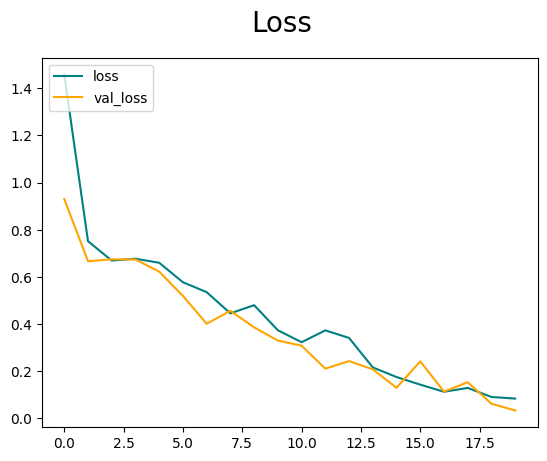

In [42]:
# Plot Performance
fig = plt.figure()
plt.plot(hist.history['loss'], color='teal', label='loss')
plt.plot(hist.history['val_loss'], color= 'orange', label='val_loss')
fig.suptitle('Loss', fontsize=20)
plt.legend(loc="upper left")
plt.show()

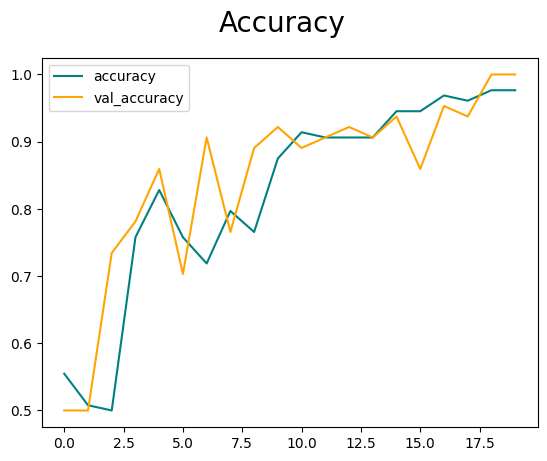

In [43]:
fig = plt.figure()
plt.plot(hist.history['accuracy'], color="teal", label="accuracy")
plt.plot(hist.history['val_accuracy'], color="orange", label="val_accuracy")
fig.suptitle("Accuracy", fontsize=20)
plt.legend(loc="upper left")
plt.show()


In [44]:
from tensorflow.keras.metrics import Precision, Recall, BinaryAccuracy

In [45]:
pre = Precision()
re = Recall()
acc= BinaryAccuracy()

In [46]:
len(test)

1

In [47]:
for batch in test.as_numpy_iterator(): 
    x, y = batch 
    yhat = model.predict(x)
    pre.update_state(y, yhat)
    re.update_state(y, yhat)
    acc.update_state(y, yhat)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step


In [48]:
print (f'Precision: {pre.result().numpy()}, Recall:{re.result().numpy()}, Accuracy:{acc.result().numpy}')

Precision: 1.0, Recall:1.0, Accuracy:<bound method _EagerTensorBase.numpy of <tf.Tensor: shape=(), dtype=float32, numpy=1.0>>


In [65]:
img = cv2.imread('sadtest.jpeg')
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.show()

error: OpenCV(4.10.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\color.cpp:196: error: (-215:Assertion failed) !_src.empty() in function 'cv::cvtColor'


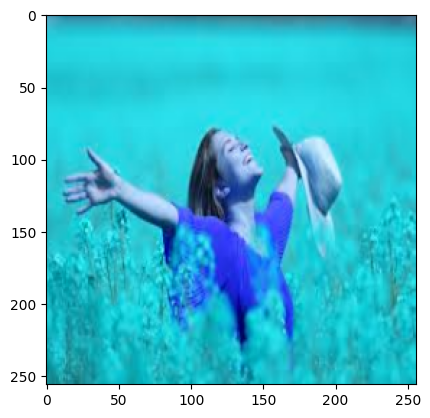

In [50]:
resize = tf.image.resize(img, (256, 256))
plt.imshow(resize.numpy().astype(int))
plt.show()

In [51]:
resize.shape

TensorShape([256, 256, 3])

In [52]:
np.expand_dims(resize, 0).shape

(1, 256, 256, 3)

In [53]:
yhat = model.predict(np.expand_dims(resize/255, 0))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step


In [54]:
yhat

array([[0.4750212]], dtype=float32)

In [55]:
if yhat > 0.5: 
    print(f'Predicted class is Sad')  
else: 
    print(f'Predicted class is Happy')

Predicted class is Happy


In [56]:
from tensorflow.keras.models import load_model

In [61]:
model.save(os.path.join('models', 'sadtest2.h5'))

In [62]:
new_model = load_model(os.path.join('models', 'sadtest2.h5'))

In [63]:
yhat = new_model.predict(np.expand_dims(resize/255, 0))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step


In [64]:
if yhat > 0.5: 
    print(f'Predicted class is Sad')  
else: 
    print(f'Predicted class is Happy')

Predicted class is Happy
